# Interpretable Heart Disease Classification

An educational comparison of RuleFit, FIGS and CART with a majority-class baseline.

**Verified label correction:** all 303 bundled records match the original UCI Cleveland records on eight identifying measurements. Bundled target=1 corresponds to UCI num=0 (absence), and target=0 to num>0 (presence). We therefore define disease_present=1-target. The audit is in reports/label_audit.json.

One duplicate is removed before the stratified 70/30 split. There are 91 test records. Missing mirror codes ca=4 and thal=0 are converted to missing values. Imputation is fitted within each training fold. Three-fold CV is confined to training rows. Features retain their original units. This is a model-comparison exercise, not a validated clinical tool.

## Setup
Run `python -m pip install -r requirements.txt` in the project folder. In Google Colab, run the setup cell below, then run `%pip install -r requirements.txt` before the analysis cell. No personal Google Drive or credentials are required.

In [1]:
from pathlib import Path
import os, subprocess
if not Path("analyze.py").exists():
    project = Path.cwd() / "HeartDiseaseModels"
    if not (project / "analyze.py").exists():
        subprocess.run(["git", "clone", "https://github.com/YirenShen-07/HeartDiseaseModels.git", str(project)], check=True)
    os.chdir(project)
print("Project:", Path.cwd().name)

Project: HeartDiseaseModels


## Source audit
This uses the original UCI endpoint to verify the bundled labels.

In [2]:
from verify_labels import verify
audit = verify()

{
  "rows_matched": 303,
  "inverted_target_agreement": 1.0,
  "original_source": "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data",
  "original_sha256": "a74b7efa387bc9d108d7d0115d831fe9b414b29ae7124f331b622b4efa0427c8",
  "bundled_sha256": "7c3014365675306819510a49ff289efbec1d1a6a666a2dc7652f1547b383d859",
  "mapping": "bundled target 1 = UCI num 0 (absence); bundled target 0 = UCI num >0 (presence)",
  "analysis_target": "disease_present = 1 - bundled target"
}


## Reproduce the analysis
The implementation lives in `analyze.py` so the CLI and notebook use the same definitions.

In [3]:
from analyze import run
results = run()
results.round(4)

                   Accuracy  Disease precision  Disease recall  Disease F1  ROC-AUC  Train CV AUC mean  Train CV AUC std
Model                                                                                                                   
Majority baseline    0.5385             0.0000          0.0000      0.0000   0.5000             0.5000            0.0000
RuleFit              0.8022             0.9000          0.6429      0.7500   0.8875             0.8976            0.0075
FIGS                 0.7692             0.7442          0.7619      0.7529   0.8540             0.8190            0.0313
CART                 0.7253             0.7073          0.6905      0.6988   0.7770             0.8476            0.0551
Out[0]: 
                   Accuracy  ...  Train CV AUC std
Model                        ...                  
Majority baseline    0.5385  ...            0.0000
RuleFit              0.8022  ...            0.0075
FIGS                 0.7692  ...            0.0313
CART      

## Results and interpretation
These plots are regenerated by the preceding cell. Metrics and split metadata are also saved to `reports/`. Results are specific to this benchmark and fixed split; business improvements have not been measured.

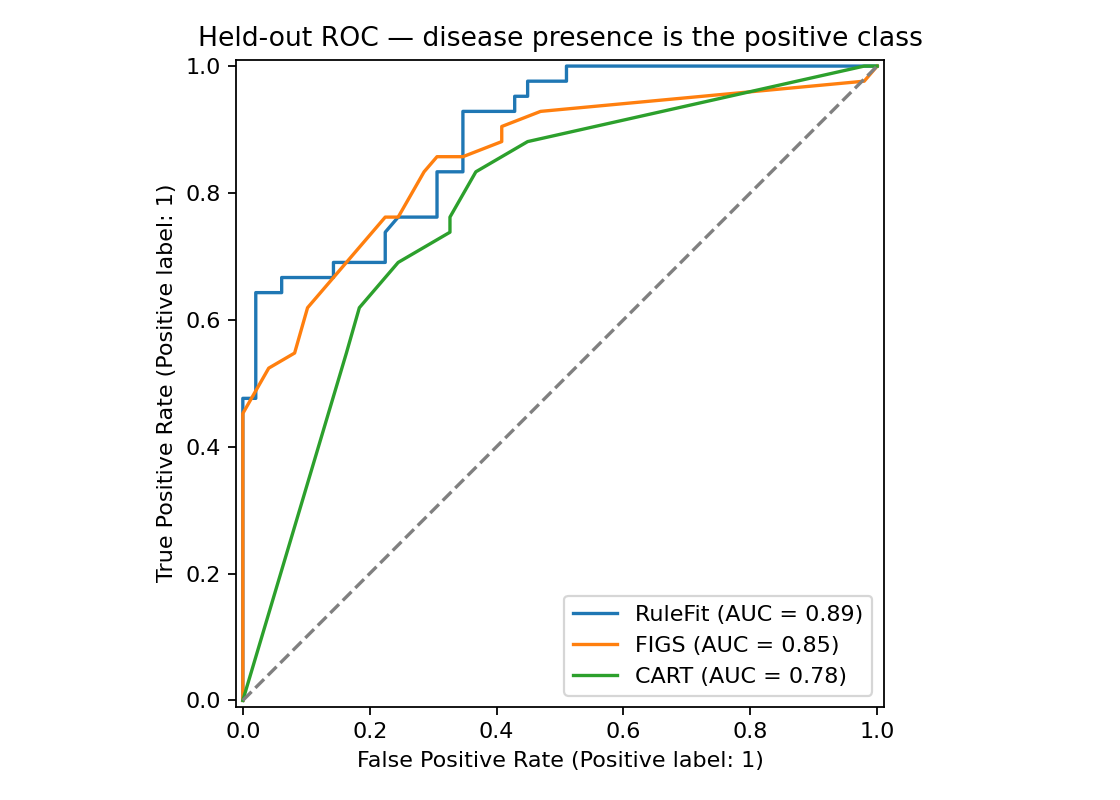

In [4]:
from IPython.display import Image, display
display(Image(filename="reports/roc_comparison.png"))

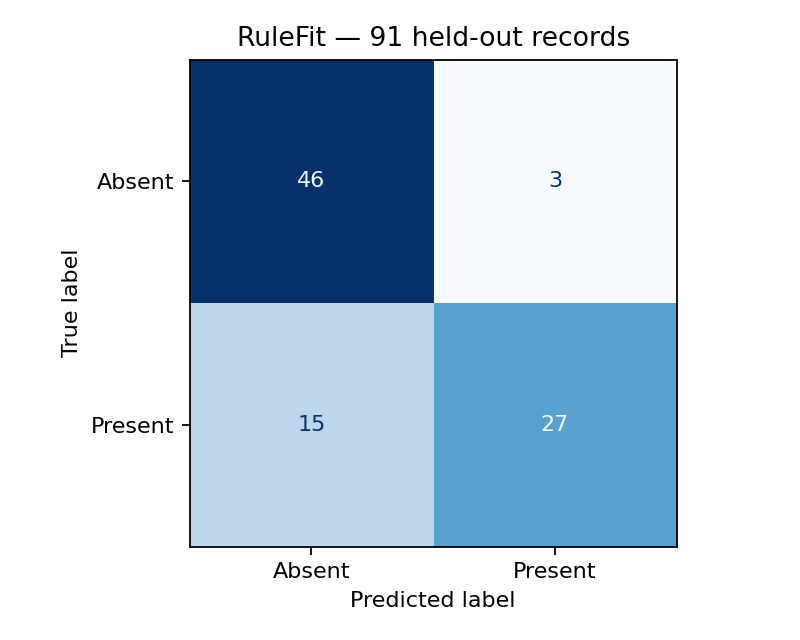

In [5]:
from IPython.display import Image, display
display(Image(filename="reports/confusion_matrix.png"))

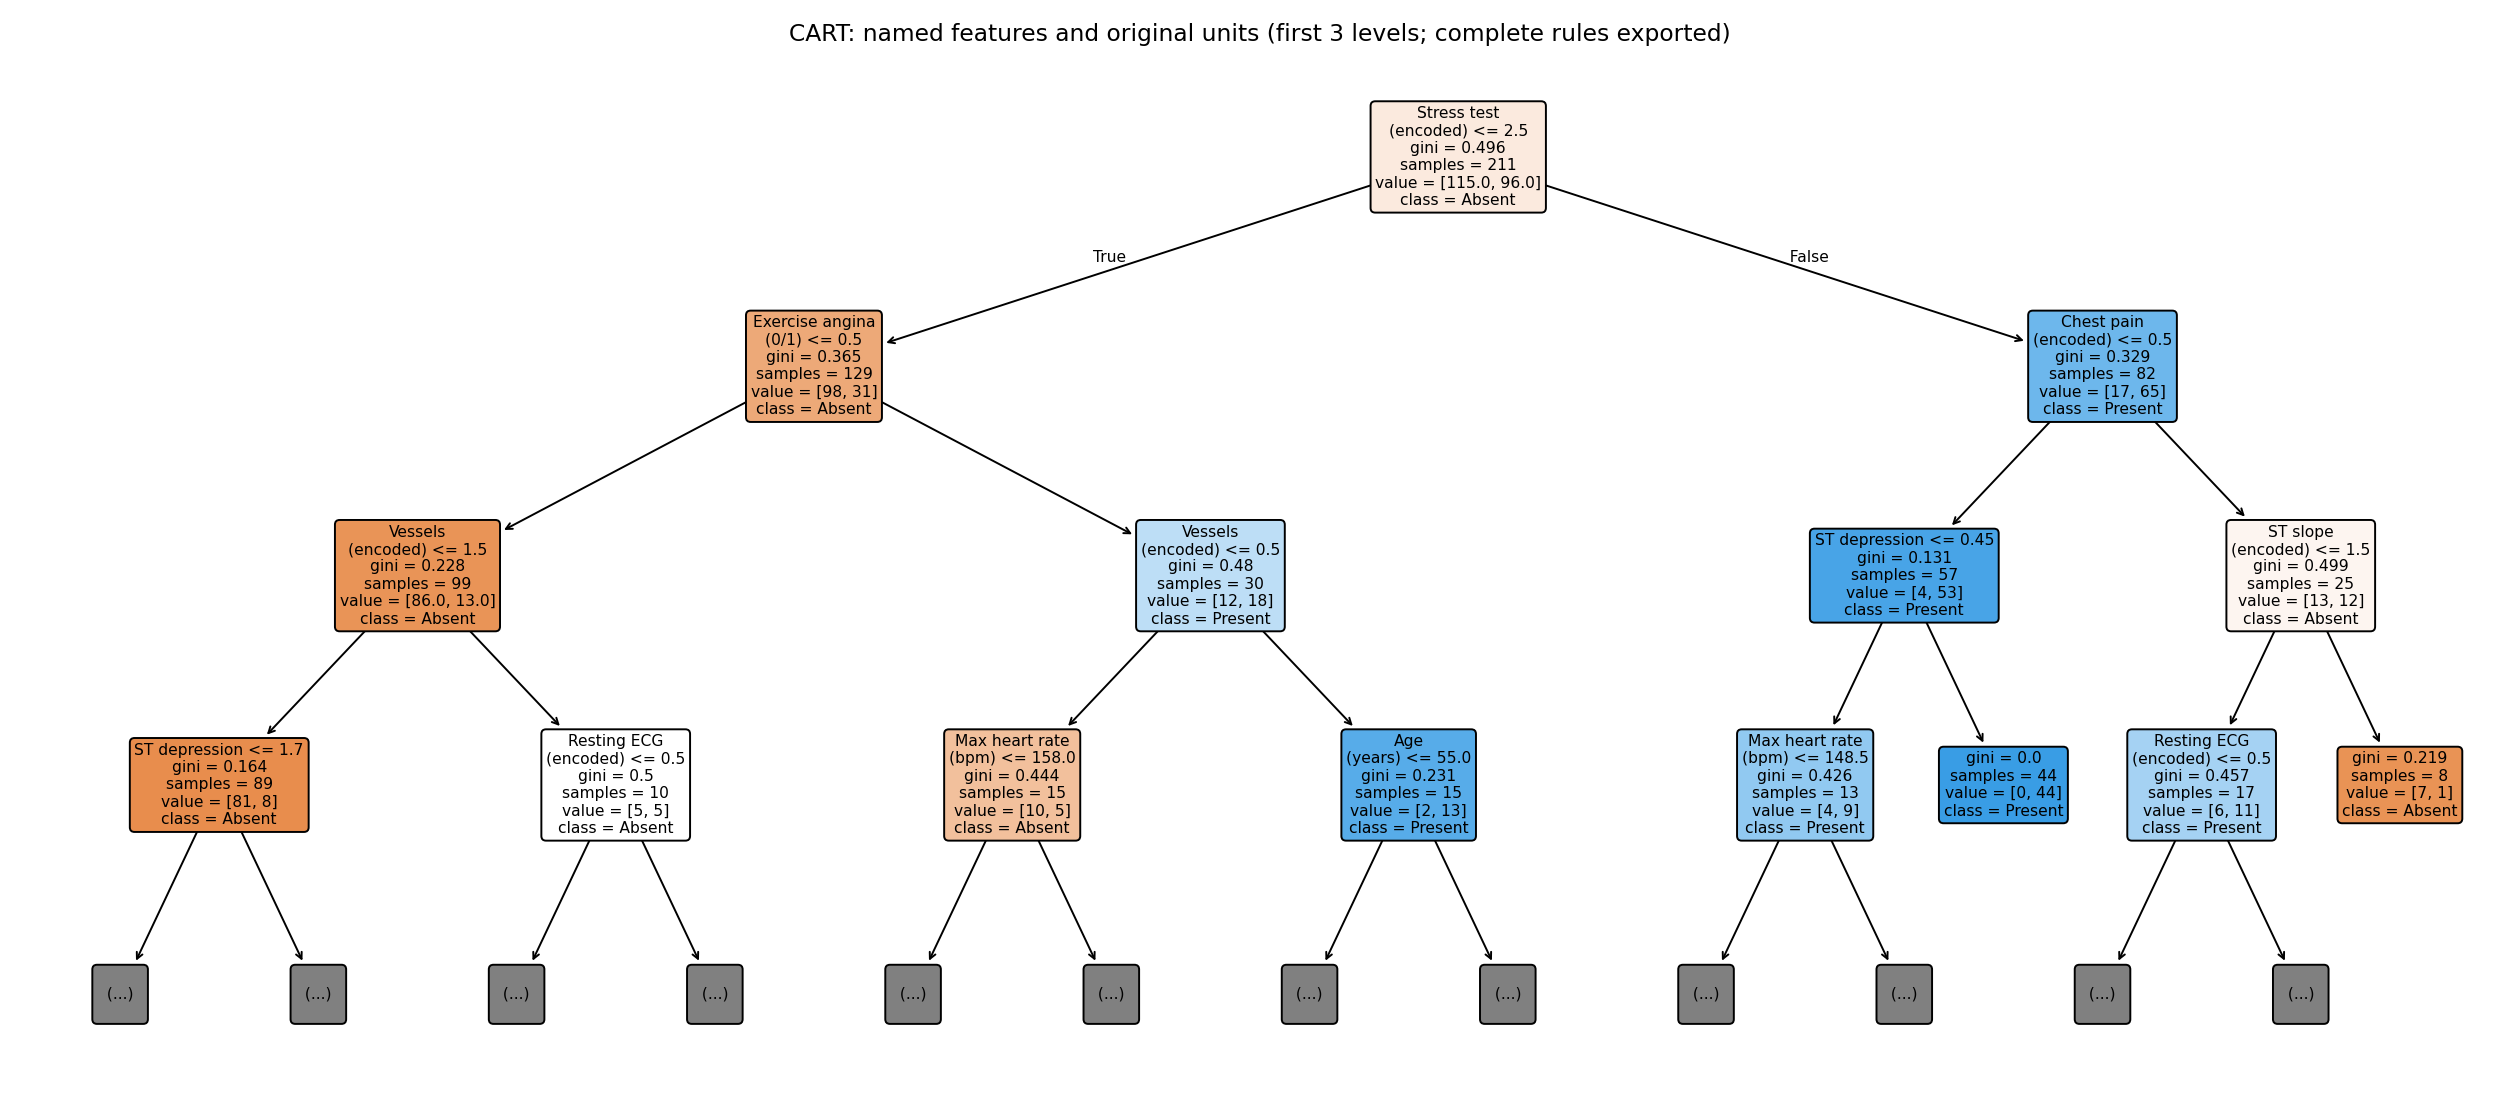

In [6]:
from IPython.display import Image, display
display(Image(filename="reports/cart_rules.png"))

## Sources and attribution
See [DATA.md](DATA.md) for sources, definitions, and fingerprints. The original project was developed by Yiren Shen for Duke AIPI 590. The 2026 portfolio maintenance pass adds reproducibility, evaluation and code corrections with AI assistance. Earlier coursework versions remain in Git history.